# Channel 통계 시각화 — Re$_\tau$ 180 / 550

`../stats_re*/` (참조 박스 재런은 `../stats_re*_ref/`) 의 최신 `channel_stats_*.dat` 와 `../log/` 모니터 로그를 읽어,
케이스별 참조 DNS(`ref_mean_*.txt`, `ref_fluc_*.txt`, 벽단위)와 겹친다.
실행하면 같은 폴더에 `*_re180.png` / `*_re550.png` 로 저장되고 **화면에도 같이 뜬다**
(노트북이면 inline, 스크립트/배치면 Agg 로 자동 전환).

⚠ **u$_\tau$ 는 파일 헤더를 믿지 않고 U_mean + 격자(면 중점 복원)로 재계산** —
zero-ghost 벽의 스킴 일관 자는 dmz (벽면↔첫중심으로 재면 √2 과대, plan §8 14-1).
참조 Re$_\tau$ 는 참조 파일의 y⁺/(y/δ) 비에서 직접 읽는다 (LM 0550 = 543.5).

**통계 누적 구간**은 stats 헤더의 `step`·`samples` 에서 복원한다 (매 스텝 누적이므로
시작 스텝 = `step − samples + 1`). ini 의 `stats_start_step` 은 런 이후 수정됐을 수
있어 쓰지 않는다 (실제로 re550 ini 는 15000 인데 파일은 12000 부터다). 복원한 구간은
모든 그림 하단에 적히고, monitor 그림에는 음영 띠로 표시된다. 시간은 모니터 로그의
step↔time 에서 보간해 코드 시간·δ/u$_\tau$(eddy turnover)·t⁺ 세 단위로 적는다.

| 그림 | 내용 | 합격 기준 |
|---|---|---|
| monitor_history (**먼저**) | Re$_\tau(t)$, div + 누적 구간 띠 | 목표 ±6% 띠 안 정착 |
| law_of_the_wall | $U^+(y^+)$ vs 참조 | 참조 곡선 위에 포개짐 |
| rms_profiles | $u'^+,v'^+,w'^+$ (+ $-\overline{u'w'}^+$) vs 참조 | 피크 위치·크기 수 % 이내 |
| shear_stress | $-\overline{u'w'}^+$ + 총전단 | 참조 u'v' 일치 + $1-z/\delta$ 직선 |

**stats 가 아직 없는 런**(진행 중)은 모니터 이력만 그려지고 프로파일 그림은
건너뛴다 — `load_monitor_only_run` 이 로그만으로 런을 만든다. 첫 stats 파일은
`stats_start_step + stats_write_interval` 스텝에서 나온다 (`step >
stats_start_step` 조건이라 `stats_start_step` 당시엔 안 쓴다).

`uw_fluct` 열은 2026-10-04 이후 런에만 있다 — 없는 런(re180 현재 파일)은 shear 그림에
점성 전단만 그리고 경고를 찍는다.

⚠ **박스 크기** — 기존 re180/re550 덱은 2π×π×2 였지만 참조 코드
(`Filtered_TDMA/apps/channel_gpu`)의 덱은 `Lx = H·Aspect1 = 4π`, `Ly = H·Aspect2 = 2π`
로 **수평 면적이 4배**다. `*_ref` 런이 그 박스를 맞춘 판이며, 중앙 2차 통계량이
DNS 보다 높던 현상의 유력 원인을 가른다.


In [1]:
import glob, math, re
import numpy as np
import matplotlib
try:                                   # 노트북: 저장 + 화면 동시
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:                      # 스크립트/배치 실행 (DISPLAY 없음)
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

run_configurations = [
    # dict(label="re180", stats_glob="../stats_re180/channel_stats_*.dat",
    #      log_glob="../log/channel_gpu_*.log", reference_suffix="180", target=180.0),
    # dict(label="re550", stats_glob="../stats_re550/channel_stats_*.dat",
    #      log_glob="../log/channel_re550_gpu_*.log", reference_suffix="550", target=550.0),
    # 참조 박스(4π×2π×2 — Filtered_TDMA channel_gpu 의 Lx=H·Aspect1) 재런.
    # stats 가 아직 없으면 load_run 이 알아서 건너뛴다.
    # code_reference: 참조 코드(Filtered_TDMA channel_gpu)가 같은 덱으로 뽑은
    # Tecplot 통계 — 있으면 코드 대 코드 곡선을 겹친다 (없으면 조용히 생략).
    # 코드-대조 파일은 격자 점 수로 케이스를 가린다 (헤더 I=...):
    #   stats_final_00030000.dat  I=256, z+/z = 180.6  -> re180
    #   stats_final_00060000.dat  I=384, z+/z = 544.1  -> re550  (LM 0550 = 543.5)
    dict(label="re180_ref", stats_glob="../stats_re180_ref/channel_stats_*.dat",
         log_glob="../log/channel_re180_ref_gpu_*.log", reference_suffix="180", target=180.0,
         code_reference="stats_final_00030000.dat"),
    dict(label="re550_ref", stats_glob="../stats_re550_ref/channel_stats_*.dat",
         log_glob="../log/channel_re550_ref_gpu_*.log", reference_suffix="550", target=550.0,
         code_reference="stats_final_00060000.dat"),
]

def load_code_reference(path, lz=2.0):
    """참조 코드(channel_gpu) Tecplot 통계 → 접기 평균 벽단위 프로파일.
    열: Z Z+ U W u_rms v_rms w_rms uw P (차원형). 참조 코드 벽 BC(ebc)는 물리
    구배라 u_tau 는 면 자(sqrt(ν·U0/z0)) — z+ 열의 암시값과 일치함을 확인했다."""
    rows = []
    for line in open(path):
        parts = line.split()
        if len(parts) == 9:
            try: rows.append([float(x) for x in parts])
            except ValueError: pass
    data = np.array(rows)
    z = data[:, 0]
    half = len(z) // 2
    y = 0.5 * (z[:half] + (lz - z[::-1][:half]))
    fold = lambda c: np.sqrt(0.5 * (data[:half, c] ** 2 + data[::-1][:half, c] ** 2))
    return dict(data=data, y=y, half=half, fold=fold)

def attach_code_reference(run):
    """run 에 code_ref_* 프로파일을 붙인다 (파일 없으면 no-op)."""
    path = run.get("code_reference")
    if not path or not glob.glob(path):
        return
    cr = load_code_reference(path, lz=2.0)
    data, half = cr["data"], cr["half"]
    nu = run["nu"]
    z, U = data[:, 0], data[:, 2]
    u_tau = math.sqrt(nu * 0.5 * (abs(U[0]) / z[0] + abs(U[-1]) / (2.0 - z[-1])))
    y = cr["y"]
    run["code_ref"] = dict(
        y_plus=y * u_tau / nu,
        u_plus=0.5 * (U[:half] + U[::-1][:half]) / u_tau,
        rms={"u'+": cr["fold"](4) / u_tau, "v'+": cr["fold"](5) / u_tau,
             "w'+": cr["fold"](6) / u_tau},
        uw_plus=0.5 * (data[:half, 7] - data[::-1][:half, 7]) / u_tau ** 2,
        re_tau=u_tau / nu, label=f"reference code (Re_tau {u_tau/nu:.1f})")
    print(f"  [{run['label']}] 코드 대조 곡선 로드: {path} (Re_tau {u_tau/nu:.1f})")

def load_monitor_block(log_glob):
    """최신 로그의 마지막 모니터 블록. 8열=구형 면-자, 9열=현행 dmz 자."""
    logs = sorted(glob.glob(log_glob))
    if not logs:
        return None, None, None
    blocks, current, n_columns = [], None, None
    for line in open(logs[-1]):
        if line.lstrip().startswith("# step"):
            current = []; blocks.append(current); continue
        parts = line.split()
        if current is not None and len(parts) in (8, 9):
            try: current.append([float(x) for x in parts]); n_columns = len(parts)
            except ValueError: pass
    block = np.array(blocks[-1]) if blocks and blocks[-1] else None
    return block, n_columns, logs[-1]

def load_monitor_only_run(configuration):
    """stats 가 아직 없는 런(진행 중) — 모니터 이력만이라도 그려 상태를 본다.
    stats 를 쓰는 프로파일 그림들은 stats_available=False 를 보고 이 런을 건너뛴다."""
    block, monitor_columns, log_path = load_monitor_block(configuration["log_glob"])
    if block is None:
        print(f"[{configuration['label']}] stats 도 모니터 로그도 없음 — 건너뜀")
        return None
    ruler_factor = math.sqrt(2) if monitor_columns == 8 else 1.0
    last_step, last_time = int(block[-1, 0]), block[-1, 1]
    last_re_tau = block[-1, 6] / ruler_factor
    run = dict(configuration, stats_available=False, monitor=block,
               monitor_columns=monitor_columns, log_path=log_path)
    run["window_text"] = (f"stats not written yet - monitor only: latest step {last_step}, "
                          f"t {last_time:.2f}, Re_tau {last_re_tau:.1f}")
    run["window_lines"] = [run["window_text"], log_path]
    print(f"[{configuration['label']}] stats 없음 (런 진행 중) — 모니터 이력만 표시: "
          f"step {last_step}, t {last_time:.2f}, Re_tau(monitor) {last_re_tau:.1f}")
    print(f"  로그: {log_path}")
    return run

def load_run(configuration):
    paths = sorted(glob.glob(configuration["stats_glob"]))
    if not paths:
        return load_monitor_only_run(configuration)
    header, rows = {}, []
    for line in open(paths[-1]):
        if line.startswith("#"):
            for key, value in re.findall(r"(\w+)=([-\d.eE+]+)", line):
                header[key] = float(value)
            continue
        rows.append([float(x) for x in line.split()])
    data = np.array(rows)
    z, u_mean = data[:, 0], data[:, 2]
    # 면 좌표 복원(중점 관계) → 스킴 일관 u_tau (dmz 자, 양벽 평균)
    faces = np.zeros(len(z) + 1)
    for q in range(len(z)):
        faces[q + 1] = 2 * z[q] - faces[q]
    nu = header["nu"]
    shear = 0.5 * nu * (abs(u_mean[0]) / (faces[1] - faces[0])
                        + abs(u_mean[-1]) / (faces[-1] - faces[-2]))
    u_tau = math.sqrt(shear)
    half_height = 0.5 * faces[-1]
    # ── 채널 대칭 접기(fold): 상·하반부를 벽거리 기준으로 평균 — 외곽역 표본 2배.
    #    U 는 대칭 평균, rms 는 분산 평균 후 √, u'w' 는 반대칭이라 부호 뒤집어 평균.
    half = len(z) // 2
    def fold_symmetric(column):
        return 0.5 * (column[:half] + column[::-1][:half])
    run = dict(configuration, stats_available=True, path=paths[-1], data=data, z=z, nu=nu,
               u_tau=u_tau, half_height=half_height,
               re_tau=u_tau * half_height / nu, half=half)
    run["y_wall"] = 0.5 * (z[:half] + (faces[-1] - z[::-1][:half]))  # 벽거리 (대칭 격자면 동일)
    run["u_fold"] = fold_symmetric(u_mean)
    run["rms_fold"] = {name: np.sqrt(fold_symmetric(data[:, column] ** 2))
                       for name, column in (("u'+", 4), ("v'+", 5), ("w'+", 6))}
    if data.shape[1] >= 8:
        run["uw_fold"] = 0.5 * (data[:half, 7] - data[::-1][:half, 7])
    run["u_mean"] = u_mean
    # ── 통계 누적 구간: 헤더가 정본. 매 스텝 누적(main.cpp §통계)이라
    #    시작 스텝 = step − samples + 1. ini 의 stats_start_step 은 런 이후
    #    바뀌었을 수 있어 쓰지 않는다.
    end_step = int(header["step"]); n_samples = int(header["samples"])
    start_step = end_step - n_samples + 1
    run.update(start_step=start_step, end_step=end_step, n_samples=n_samples)
    # ── 모니터 로그에서 step↔time 보간 → 누적 구간을 시간 단위로도 환산
    block, monitor_columns, log_path = load_monitor_block(configuration["log_glob"])
    run.update(monitor=block, monitor_columns=monitor_columns, log_path=log_path)
    # 그림에 찍히는 문자열은 ASCII/그리스 문자만 — DejaVu Sans 에 한글 글리프가 없다
    window = f"stats accumulated: step {start_step}-{end_step} ({n_samples} samples, every step)"
    if block is not None:
        steps, times = block[:, 0], block[:, 1]
        clipped = start_step < steps[0] - 0.5 or end_step > steps[-1] + 0.5
        t_start, t_end = np.interp([start_step, end_step], steps, times)
        duration = t_end - t_start
        run.update(t_start=t_start, t_end=t_end, duration=duration,
                   eddy_turnovers=duration * u_tau / half_height,
                   duration_plus=duration * u_tau ** 2 / nu, window_clipped=clipped)
        window += ("  |  t {}{:.2f}-{:.2f}  (Δt {:.2f} = {:.2f} δ/u_τ = {:.0f} t+)"
                   .format("~" if clipped else "", t_start, t_end, duration,
                           run["eddy_turnovers"], run["duration_plus"]))
    run["window_text"] = window
    # 그림용은 두 줄로 쪼갠다 — 5.6인치 폭에 한 줄로는 잘린다
    run["window_lines"] = window.split("  |  ")
    # 참조 (벽단위): mean = y/d, y+, U+ ...  / fluc = y/d, y+, u'u', v'v', w'w', u'v'...
    suffix = configuration["reference_suffix"]
    run["reference_mean"] = np.loadtxt(f"ref_mean_{suffix}.txt", comments="%")
    run["reference_fluctuation"] = np.loadtxt(f"ref_fluc_{suffix}.txt", comments="%")
    rm = run["reference_mean"]
    run["reference_re_tau"] = float(rm[-1, 1] / rm[-1, 0])  # y+/(y/d) = Re_tau
    print(f"[{configuration['label']}] {paths[-1]}")
    print(f"  u_tau(dmz) = {u_tau:.5f} -> Re_tau = {run['re_tau']:.1f}   "
          f"(reference {run['reference_re_tau']:.1f}, "
          f"{100*(run['re_tau']/run['reference_re_tau']-1):+.1f}%)")
    print(f"  누적 구간  : {run['window_text']}")
    attach_code_reference(run)
    print(f"  uw_fluct 열: {'있음' if 'uw_fold' in run else '없음 (구형 stats — 재런 필요)'}"
          f"   스냅샷: " + ", ".join(
              f"{int(p.split('_')[-1].split('.')[0])}" for p in paths))
    return run

def annotate_window(figure, run):
    """모든 그림 하단에 누적 구간을 같은 형식으로 적는다."""
    figure.text(0.5, 0.006, "\n".join(run["window_lines"]), ha="center",
                va="bottom", fontsize=7, color="0.35", linespacing=1.4)

runs = [r for r in (load_run(c) for c in run_configurations) if r]
assert runs, "어느 런의 stats 도 모니터 로그도 없다"


[re180_ref] ../stats_re180_ref/channel_stats_00060000.dat
  u_tau(dmz) = 0.06331 -> Re_tau = 180.9   (reference 182.1, -0.7%)
  누적 구간  : stats accumulated: step 20000-60000 (40001 samples, every step)  |  t 234.86-741.59  (Δt 506.73 = 32.08 δ/u_τ = 5802 t+)
  [re180_ref] 코드 대조 곡선 로드: stats_final_00030000.dat (Re_tau 180.9)
  uw_fluct 열: 있음   스냅샷: 25000, 30000, 35000, 40000, 45000, 50000, 55000, 60000
[re550_ref] ../stats_re550_ref/channel_stats_00040000.dat
  u_tau(dmz) = 0.05406 -> Re_tau = 540.6   (reference 543.5, -0.5%)
  누적 구간  : stats accumulated: step 30000-40000 (10001 samples, every step)  |  t 122.56-166.78  (Δt 44.22 = 2.39 δ/u_τ = 1292 t+)
  [re550_ref] 코드 대조 곡선 로드: stats_final_00060000.dat (Re_tau 542.9)
  uw_fluct 열: 있음   스냅샷: 40000


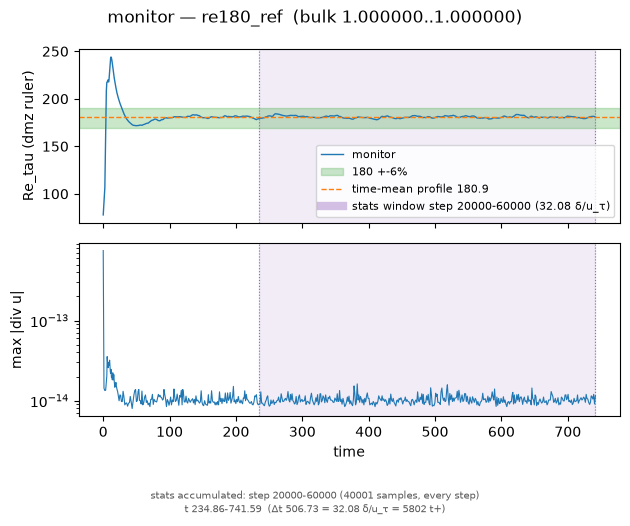

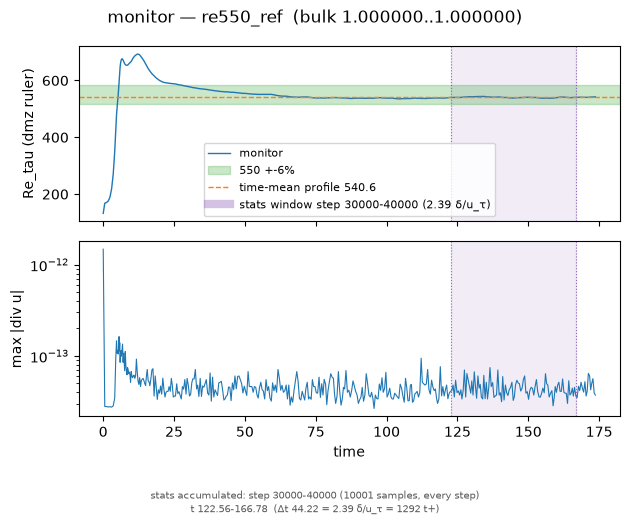

In [2]:
# 모니터 이력 — 8열(구형 면-자: /sqrt2 환산) / 9열(현행 dmz 자) 모두 지원.
# ★ 제일 먼저 보는 그림: 런이 살아 있나 · 목표 Re_tau 에 정착했나 · div 가 머무나.
#   stats 가 아직 없는 진행 중 런도 여기엔 나온다 (프로파일 그림만 건너뛴다).
# 통계 누적 구간은 음영 띠 + 세로선으로 표시 (블록은 cell 1 에서 이미 읽어뒀다).
for run in runs:
    block, n_columns = run["monitor"], run["monitor_columns"]
    if block is None:
        print(f"[{run['label']}] 모니터 행 없음 ({run['log_path']})"); continue
    ruler_factor = math.sqrt(2) if n_columns == 8 else 1.0
    time, bulk, divergence = block[:, 1], block[:, 3], block[:, 4]
    re_tau_history = block[:, 6] / ruler_factor
    figure, (axis_re, axis_div) = plt.subplots(2, 1, figsize=(6.4, 5.2), sharex=True)
    axis_re.plot(time, re_tau_history, lw=1,
                 label="monitor" + (" (/sqrt2 ruler-converted)" if n_columns == 8 else ""))
    axis_re.axhspan(run["target"] * 0.94, run["target"] * 1.06, color="tab:green",
                    alpha=0.25, label=f"{run['target']:.0f} +-6%")
    if run["stats_available"]:
        axis_re.axhline(run["re_tau"], color="tab:orange", lw=1, ls="--",
                        label=f"time-mean profile {run['re_tau']:.1f}")
        for axis in (axis_re, axis_div):   # 누적 구간 띠 (양 패널 동일)
            axis.axvspan(run["t_start"], run["t_end"], color="tab:purple",
                         alpha=0.12, zorder=0)
            for boundary in (run["t_start"], run["t_end"]):
                axis.axvline(boundary, color="tab:purple", lw=0.8, ls=":")
        axis_re.plot([], [], color="tab:purple", alpha=0.4, lw=6,
                     label=(f"stats window step {run['start_step']}-{run['end_step']} "
                            f"({run['eddy_turnovers']:.2f} δ/u_τ)"))
    else:                              # 진행 중 런 — 누적 구간이 아직 없다
        axis_re.plot(time[-1], re_tau_history[-1], "o", color="tab:red", ms=5,
                     label=f"latest step {int(block[-1, 0])} (stats not written yet)")
    axis_re.set_ylabel("Re_tau (dmz ruler)"); axis_re.legend(fontsize=8)
    axis_div.semilogy(time, divergence, lw=0.8)
    axis_div.set_xlabel("time"); axis_div.set_ylabel("max |div u|")
    figure.suptitle(f"monitor — {run['label']}  (bulk {bulk.min():.6f}..{bulk.max():.6f})")
    figure.tight_layout(rect=(0, 0.085, 1, 1))
    annotate_window(figure, run)
    # figure.savefig(f"monitor_history_{run['label']}.png", dpi=150)
    plt.show()


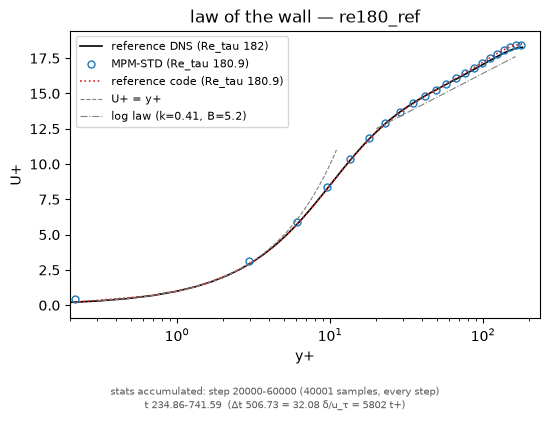

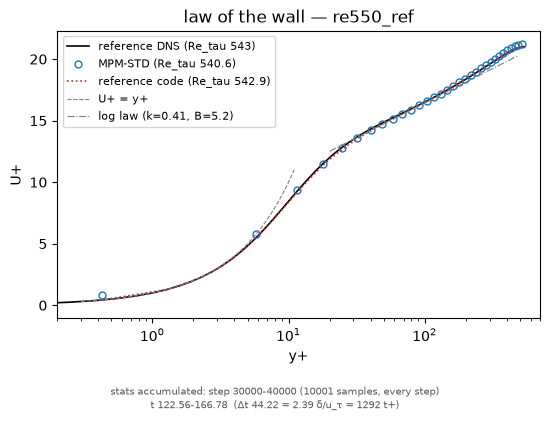

In [8]:
for run in runs:
    if not run["stats_available"]:
        print(f"[{run['label']}] stats 없음 — law of the wall 생략"); continue
    half, u_tau, nu = run["half"], run["u_tau"], run["nu"]
    y_plus = run["y_wall"] * u_tau / nu          # 접기 평균 (상·하반부)
    u_plus = run["u_fold"] / u_tau
    figure, axis = plt.subplots(figsize=(5.6, 4.2))
    axis.semilogx(run["reference_mean"][:, 1], run["reference_mean"][:, 2], "k-",
                  lw=1.2, label=f"reference DNS (Re_tau {run['reference_re_tau']:.0f})")
    axis.semilogx(y_plus[::3], u_plus[::3], "o", ms=5, mfc="none", markevery=2,
                  label=f"MPM-STD (Re_tau {run['re_tau']:.1f})")
    if "code_ref" in run:
        cr = run["code_ref"]
        axis.semilogx(cr["y_plus"], cr["u_plus"], ":", color="tab:red", lw=1.2,
                      label=cr["label"])
    sublayer = np.linspace(0.3, 11, 50)
    axis.semilogx(sublayer, sublayer, "--", color="gray", lw=0.8, label="U+ = y+")
    log_region = np.linspace(20, 0.9 * run["re_tau"], 60)
    axis.semilogx(log_region, np.log(log_region) / 0.41 + 5.2, "-.", color="gray",
                  lw=0.8, label="log law (k=0.41, B=5.2)")
    axis.set_xlim(0.2, 1.3 * run["re_tau"]); axis.set_xlabel("y+"); axis.set_ylabel("U+")
    axis.set_title(f"law of the wall — {run['label']}")
    axis.legend(fontsize=8); figure.tight_layout(rect=(0, 0.085, 1, 1))
    annotate_window(figure, run)
    # figure.savefig(f"law_of_the_wall_{run['label']}.png", dpi=150)
    plt.show()


[re180_ref] u'+ peak: MPM-STD 2.60 @ y+ 14.2  /  reference 2.67 @ y+ 14.6


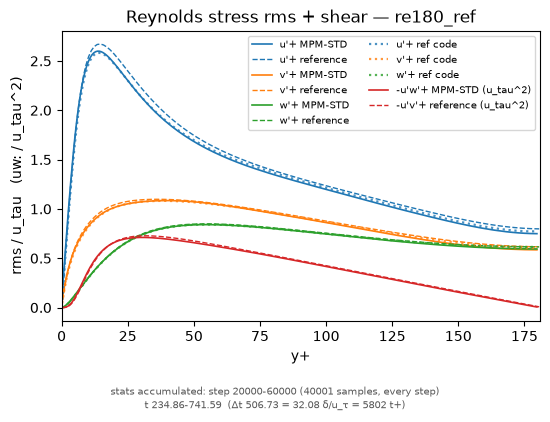

[re550_ref] u'+ peak: MPM-STD 2.74 @ y+ 13.6  /  reference 2.77 @ y+ 14.8


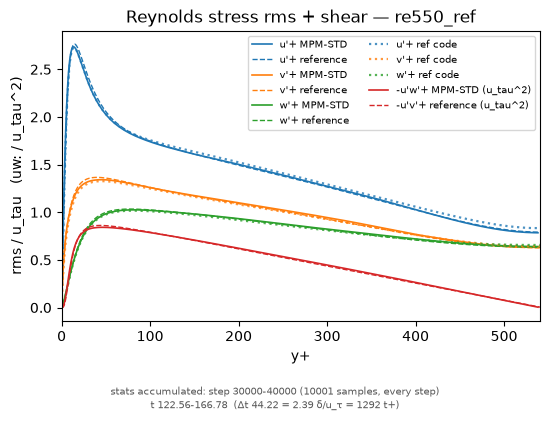

In [4]:
# rms — 참조 u'u',w'w',v'v' 분산(벽단위). 좌표 매핑: 참조 v=벽수직↔우리 w(z),
# 참조 w=스팬↔우리 v(y).  u'w' 가 있는 런은 레이놀즈 전단도 같은 패널에 겹친다
# (단위는 u_tau^2 — rms(u_tau) 와 다르니 라벨에 명시).
for run in runs:
    if not run["stats_available"]:
        print(f"[{run['label']}] stats 없음 — rms 그림 생략"); continue
    half, u_tau = run["half"], run["u_tau"]
    y_plus = run["y_wall"] * u_tau / run["nu"]   # 접기 평균
    rf = run["reference_fluctuation"]
    reference_rms = {"u'+": np.sqrt(rf[:, 2]), "v'+": np.sqrt(rf[:, 4]),
                     "w'+": np.sqrt(rf[:, 3])}
    ours = run["rms_fold"]
    figure, axis = plt.subplots(figsize=(5.6, 4.2))
    for (name, values), color in zip(ours.items(),
                                     ("tab:blue", "tab:orange", "tab:green")):
        axis.plot(y_plus, values / u_tau, color=color, lw=1.2,
                  label=f"{name} MPM-STD")
        axis.plot(rf[:, 1], reference_rms[name], color=color, ls="--", lw=1,
                  label=f"{name} reference")
    if "code_ref" in run:
        cr = run["code_ref"]
        for (name, values), color in zip(cr["rms"].items(),
                                         ("tab:blue", "tab:orange", "tab:green")):
            axis.plot(cr["y_plus"], values, color=color, ls=":", lw=1.6, alpha=0.8,
                      label=f"{name} ref code")
    if "uw_fold" in run:
        axis.plot(y_plus, -run["uw_fold"] / u_tau**2, color="tab:red", lw=1.2,
                  label="-u'w'+ MPM-STD (u_tau^2)")
        axis.plot(rf[:, 1], -rf[:, 5], color="tab:red", ls="--", lw=1,
                  label="-u'v'+ reference (u_tau^2)")
    else:
        print(f"[{run['label']}] uw_fluct 열 없음 — rms 패널에 레이놀즈 전단 생략")
    streamwise = "u'+"            # f-string 안에 따옴표 중첩을 피하려 이름을 변수로
    peak_index = int(np.argmax(ours[streamwise]))
    reference_peak = int(np.argmax(reference_rms[streamwise]))
    print(f"[{run['label']}] u'+ peak: MPM-STD "
          f"{ours[streamwise][peak_index]/u_tau:.2f} @ y+ {y_plus[peak_index]:.1f}"
          f"  /  reference {reference_rms[streamwise].max():.2f} @ y+ "
          f"{rf[reference_peak, 1]:.1f}")
    axis.set_xlim(0, run["re_tau"])
    axis.set_xlabel("y+"); axis.set_ylabel("rms / u_tau   (uw: / u_tau^2)")
    axis.set_title(f"Reynolds stress rms + shear — {run['label']}")
    axis.legend(fontsize=7, ncol=2); figure.tight_layout(rect=(0, 0.085, 1, 1))
    annotate_window(figure, run)
    # figure.savefig(f"rms_profiles_{run['label']}.png", dpi=150)
    plt.show()


[re180_ref] -u'w'+ peak: MPM-STD 0.711 @ y+ 30.5  /  reference 0.728 @ y+ 32.3


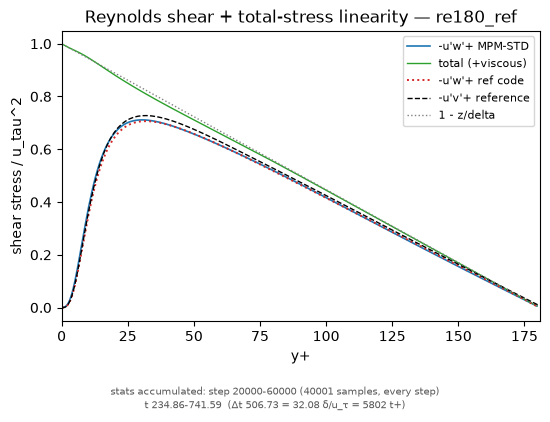

[re550_ref] -u'w'+ peak: MPM-STD 0.842 @ y+ 45.7  /  reference 0.862 @ y+ 43.0


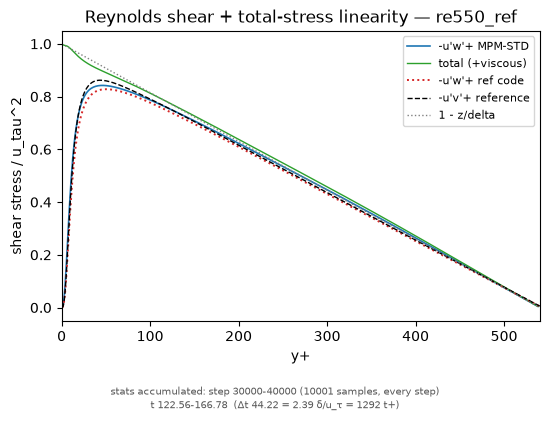

In [5]:
# 레이놀즈 전단 + 총전단 선형성. uw_fluct 열이 없는 구형 stats(re180 현재 파일)는
# 점성 전단과 참조만 그려 무엇이 빠졌는지 그림에서 바로 보이게 한다.
for run in runs:
    if not run["stats_available"]:
        print(f"[{run['label']}] stats 없음 — shear 그림 생략"); continue
    half, u_tau = run["half"], run["u_tau"]
    y_plus = run["y_wall"] * u_tau / run["nu"]   # 접기 평균 (u'w' 는 반대칭 fold)
    rf = run["reference_fluctuation"]
    viscous = run["nu"] * np.gradient(run["u_fold"], run["y_wall"]) / u_tau**2
    figure, axis = plt.subplots(figsize=(5.6, 4.2))
    if "uw_fold" in run:
        uw_plus = -run["uw_fold"] / u_tau**2
        axis.plot(y_plus, uw_plus, lw=1.2, label="-u'w'+ MPM-STD")
        axis.plot(y_plus, uw_plus + viscous, lw=1, color="tab:green",
                  label="total (+viscous)")
        ours_peak = int(np.argmax(uw_plus)); reference_peak = int(np.argmax(-rf[:, 5]))
        print(f"[{run['label']}] -u'w'+ peak: MPM-STD {uw_plus[ours_peak]:.3f} @ y+ "
              f"{y_plus[ours_peak]:.1f}  /  reference {-rf[reference_peak, 5]:.3f} @ y+ "
              f"{rf[reference_peak, 1]:.1f}")
    else:
        axis.plot(y_plus, viscous, lw=1.2, color="tab:green",
                  label="viscous only (no uw_fluct column)")
        print(f"[{run['label']}] uw_fluct 열 없음 ({run['path']}) — 점성 전단만 표시. "
              f"uw 는 2026-10-04 이후 런에서만 기록된다")
    if "code_ref" in run:
        cr = run["code_ref"]
        axis.plot(cr["y_plus"], -cr["uw_plus"], ":", color="tab:red", lw=1.4,
                  label="-u'w'+ ref code")
    axis.plot(rf[:, 1], -rf[:, 5], "k--", lw=1, label="-u'v'+ reference")
    axis.plot(y_plus, 1 - run["y_wall"] / run["half_height"], ":", color="gray",
              lw=1, label="1 - z/delta")
    axis.set_xlim(0, run["re_tau"]); axis.set_xlabel("y+")
    axis.set_ylabel("shear stress / u_tau^2")
    axis.set_title(f"Reynolds shear + total-stress linearity — {run['label']}")
    axis.legend(fontsize=8); figure.tight_layout(rect=(0, 0.085, 1, 1))
    annotate_window(figure, run)
    # figure.savefig(f"shear_stress_{run['label']}.png", dpi=150)
    plt.show()
